In [12]:
import sys 
sys.path.append("../")
import os
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import pymk as pymk #mine
import utils
import matplotlib.dates as mdates
import datetime
from shapely.geometry import Polygon, Point, box
from shapely.ops import unary_union
import matplotlib.gridspec as gridspec


In [2]:
bathy_alb = xr.open_dataset('../../data/006_004_medmfc_bathy_alb.nc')
hflux_alb = xr.open_dataset('../../data/006_004_medmfc_hflux_alb.nc')
mflux_alb = xr.open_dataset('../../data/006_004_medmfc_mflux_alb.nc')
mld_alb = xr.open_dataset('../../data/006_004_medmfc_mld_alb.nc')
so_alb = xr.open_dataset('../../data/006_004_medmfc_so_alb.nc')
ssh_alb = xr.open_dataset('../../data/006_004_medmfc_ssh_alb.nc')
thetao_alb = xr.open_dataset('../../data/006_004_medmfc_thetao_alb.nc')
uovo_alb = xr.open_dataset('../../data/006_004_medmfc_uovo_alb.nc')

bathy_iera = xr.open_dataset('../../data/006_004_medmfc_bathy_iera.nc')
hflux_iera = xr.open_dataset('../../data/006_004_medmfc_hflux_iera.nc')
mflux_iera = xr.open_dataset('../../data/006_004_medmfc_mflux_iera.nc')
mld_iera = xr.open_dataset('../../data/006_004_medmfc_mld_iera.nc')
so_iera = xr.open_dataset('../../data/006_004_medmfc_so_iera.nc')
ssh_iera = xr.open_dataset('../../data/006_004_medmfc_ssh_iera.nc')
thetao_iera = xr.open_dataset('../../data/006_004_medmfc_thetao_iera.nc')
uovo_iera = xr.open_dataset('../../data/006_004_medmfc_uovo_iera.nc')
#Car je n'ai pas pu enregistré uovo_iera2, l'ordi plante
valid_depth = bathy_iera.mask.any(dim=["latitude", "longitude"])
bathy_iera = bathy_iera.sel(depth=valid_depth)
uovo_iera = uovo_iera.sel(depth=valid_depth)

In [ ]:
#to delete unuseful depth levels
valid_depth = bathy_alb.mask.any(dim=["latitude", "longitude"])
bathy_alb = bathy_alb.sel(depth=valid_depth)
so_alb = so_alb.sel(depth=valid_depth)
thetao_alb = thetao_alb.sel(depth=valid_depth)
uovo_alb = uovo_alb.sel(depth=valid_depth)

bathy_alb.to_netcdf('../../data/006_004_medmfc_bathy_alb2.nc')
so_alb.to_netcdf('../../data/006_004_medmfc_so_alb2.nc')
thetao_alb.to_netcdf('../../data/006_004_medmfc_thetao_alb2.nc')
uovo_alb.to_netcdf('../../data/006_004_medmfc_uovo_alb2.nc')



valid_depth = bathy_iera.mask.any(dim=["latitude", "longitude"])
so_iera = so_iera.sel(depth=valid_depth)
thetao_iera = thetao_iera.sel(depth=valid_depth)

so_iera.to_netcdf('../../data/006_004_medmfc_so_iera2.nc')
thetao_iera.to_netcdf('../../data/006_004_medmfc_thetao_iera2.nc')

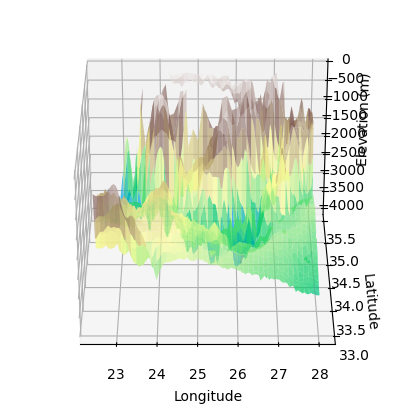

In [ ]:
#plot bathymetry
lon = bathy_iera['longitude'].values
lat = bathy_iera['latitude'].values
elev = -bathy_iera['deptho'].values
Lon, Lat = np.meshgrid(lon, lat)
fig = plt.figure(figsize=(5,5))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(Lon, Lat, elev, cmap='terrain', alpha=0.7)
ax.view_init(elev=30, azim=270)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_zlabel('Elevation (m)')
plt.show()


In [4]:
# ============================================================
# 1. CONSTRUIRE LE POLYGONE IERAPETRA DEPUIS LE MASQUE EKE
# ============================================================

mask = np.load(
    '../../../Med_Global_EKE/results/masks/2mask_IERAISO_MED.npy',
    allow_pickle=True
)

ekem = xr.open_dataset(
    '../../../Med_Global_EKE/processed_data/MED/ALL_SAT/'
    'NEKE_ALL_SAT_MED_C3S_vDT2021_19930101_20230607.nc'
)

meanekem = ekem.mean(dim='time', skipna=False)

lon = meanekem['lon'].values
lat = meanekem['lat'].values

# Résolution de la grille EKE
dlon = np.abs(np.diff(lon).mean())
dlat = np.abs(np.diff(lat).mean())

half_dlon = dlon / 2
half_dlat = dlat / 2


# ============================================================
# 2. CONSTRUIRE LES CELLULES DU MASQUE
# ============================================================

cells = []

for j, lat0 in enumerate(lat):
    for i, lon0 in enumerate(lon):

        if mask[j, i]:

            cell = box(
                lon0 - half_dlon,
                lat0 - half_dlat,
                lon0 + half_dlon,
                lat0 + half_dlat
            )

            cells.append(cell)


# Fusionner toutes les cellules
polygon_iera = unary_union(cells)


# ============================================================
# 3. PRENDRE UNIQUEMENT LA SURFACE DE UOVO
# ============================================================

uovo_surface = uovo_iera.isel(depth=0)


# ============================================================
# 4. RESOLUTION DE LA GRILLE UOVO
# ============================================================

lat_uovo = uovo_surface["latitude"].values
lon_uovo = uovo_surface["longitude"].values

dlon_uovo = np.abs(np.diff(lon_uovo).mean())
dlat_uovo = np.abs(np.diff(lat_uovo).mean())

half_dlon_uovo = dlon_uovo / 2
half_dlat_uovo = dlat_uovo / 2


# ============================================================
# 5. CONSTRUIRE LE MASQUE À LA RESOLUTION DE UOVO
# ============================================================

mask_uovo = np.zeros(
    (len(lat_uovo), len(lon_uovo)),
    dtype=bool
)

for j, lat0 in enumerate(lat_uovo):

    for i, lon0 in enumerate(lon_uovo):

        cell = box(
            lon0 - half_dlon_uovo,
            lat0 - half_dlat_uovo,
            lon0 + half_dlon_uovo,
            lat0 + half_dlat_uovo
        )

        if cell.intersects(polygon_iera):
            mask_uovo[j, i] = True


# ============================================================
# 6. CONVERTIR LE MASQUE EN XARRAY
# ============================================================

mask_uovo = xr.DataArray(
    mask_uovo,
    coords={
        "latitude": uovo_surface["latitude"],
        "longitude": uovo_surface["longitude"]
    },
    dims=("latitude", "longitude"),
    name="mask_iera"
)


# ============================================================
# 7. APPLIQUER LE MASQUE
# ============================================================

uovo_iera_masked = uovo_surface.where(mask_uovo)

In [5]:
uo_surf = uovo_iera_masked.uo
vo_surf = uovo_iera_masked.vo
uoa_surf = uo_surf - uo_surf.mean(dim='time')
voa_surf = vo_surf - vo_surf.mean(dim='time')
eke_surf_iera = 0.5 * (uoa_surf**2 + voa_surf**2)*10000

uo_surf = uovo_alb.uo[:,0,:,:]
vo_surf = uovo_alb.vo[:,0,:,:]
uoa_surf = uo_surf - uo_surf.mean(dim='time')
voa_surf = vo_surf - vo_surf.mean(dim='time')
eke_surf_alb = 0.5 * (uoa_surf**2 + voa_surf**2)*10000

In [ ]:
area = utils.get_area_haversine(eke_surf_iera['latitude'], eke_surf_iera['longitude'])
da_area = xr.Dataset(coords={'latitude': eke_surf_iera.latitude, 'longitude': eke_surf_iera.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(eke_surf_iera.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekesurf_iera = (eke_surf_iera * area_rat).sum(['latitude', 'longitude']).compute()

area = utils.get_area_haversine(eke_surf_alb['latitude'], eke_surf_alb['longitude'])
da_area = xr.Dataset(coords={'latitude': eke_surf_alb.latitude, 'longitude': eke_surf_alb.longitude})
da_area['area'] = (('latitude', 'longitude'), area)
area = da_area['area'].where(eke_surf_alb.notnull().any(dim='time'))
area_sum = area.sum(['latitude', 'longitude']).compute()
area_rat = area/area_sum
ds_meanekesurf_alb = (eke_surf_alb * area_rat).sum(['latitude', 'longitude']).compute()


In [7]:
def pmk_test(ts):
    if np.isnan(ts).all():
        return np.nan, np.nan, np.nan, np.nan
    results = pymk.yue_wang_modification_test(ts)
    slope, p_value, n_ns, intercept = results.slope, results.p, results.n_ns, results.intercept
    return slope, p_value, n_ns, intercept

def std_mktrend(tseries, slope, intercept, ESS):

    x = np.arange(len(tseries))
    y_pred = (slope/365) * x + intercept
    
    residuals = tseries - y_pred
    std = 365*np.sqrt(np.sum(residuals**2) / (ESS - 2)) / np.sqrt(np.sum((x - np.mean(x))**2))

    return std

In [8]:
sliera, piera, nnsiera, interiera = pmk_test(ds_meanekesurf_iera)*np.array((365,1,1,1))
incertiera = std_mktrend(ds_meanekesurf_iera, sliera, interiera, len(ds_meanekesurf_iera)/nnsiera)

slalb, palb, nnsalb, interalb = pmk_test(ds_meanekesurf_alb)*np.array((365,1,1,1))
incertalb = std_mktrend(ds_meanekesurf_alb, slalb, interalb, len(ds_meanekesurf_alb)/nnsalb)

In [ ]:
# Satellites
ekem = xr.open_dataset('../../../Med_Global_EKE/processed_data/MED/ALL_SAT/NEKE_ALL_SAT_MED_C3S_vDT2021_19930101_20230607.nc')
ekea = xr.open_dataset('../../../Med_Global_EKE/processed_data/GLO/ALL_SAT/NEKE_ALL_SAT_GLO_C3S_vDT2021_19930101_20230607.nc')
eket = xr.open_dataset('../../../Med_Global_EKE/processed_data/GLO/TWO_SAT/NEKE_TWO_SAT_GLO_C3S_vDT2021_19930101_20230607.nc')
#
maskalbm = np.load('../../../Med_Global_EKE/results/masks/2mask_ALB_MED.npy', allow_pickle=True)
maskalbg = np.load('../../../Med_Global_EKE/results/masks/2mask_ALB_GLO.npy', allow_pickle=True)
ekem_alb = ekem.where(maskalbm)
ekea_alb = ekea.where(maskalbg)
eket_alb = eket.where(maskalbg)
maskierabm = np.load('../../../Med_Global_EKE/results/masks/2mask_IERAISO_MED.npy', allow_pickle=True)
maskierabg = np.load('../../../Med_Global_EKE/results/masks/2mask_IERAISO_GLO.npy', allow_pickle=True)
ekem_ierab = ekem.where(maskierabm)
ekea_ierab = ekea.where(maskierabg)
eket_ierab = eket.where(maskierabg)
#
area = utils.get_area_haversine(ekem_alb['lat'], ekem_alb['lon'])
da_area = xr.Dataset(coords={'lat': ekem_alb.lat, 'lon': ekem_alb.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekem_alb.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsm_alb = (ekem_alb * area_rat).sum(['lat', 'lon']).compute()

area = utils.get_area_haversine(ekea_alb['lat'], ekea_alb['lon'])
da_area = xr.Dataset(coords={'lat': ekea_alb.lat, 'lon': ekea_alb.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekea_alb.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsa_alb = (ekea_alb * area_rat).sum(['lat', 'lon']).compute()
dst_alb = (eket_alb * area_rat).sum(['lat', 'lon']).compute()


area = utils.get_area_haversine(ekem_ierab['lat'], ekem_ierab['lon'])
da_area = xr.Dataset(coords={'lat': ekem_ierab.lat, 'lon': ekem_ierab.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekem_ierab.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsm_ierab = (ekem_ierab * area_rat).sum(['lat', 'lon']).compute()

area = utils.get_area_haversine(ekea_ierab['lat'], ekea_ierab['lon'])
da_area = xr.Dataset(coords={'lat': ekea_ierab.lat, 'lon': ekea_ierab.lon})
da_area['area'] = (('lat', 'lon'), area)
area = da_area['area'].where(ekea_ierab.EKE.notnull().any(dim='time'))
area_sum = area.sum(['lat', 'lon']).compute()
area_rat = area/area_sum
dsa_ierab = (ekea_ierab * area_rat).sum(['lat', 'lon']).compute()
dst_ierab = (eket_ierab * area_rat).sum(['lat', 'lon']).compute()
#
sla_alb, pa_alb, nnsa_alb, intera_alb = pmk_test(dsa_alb.EKE)*np.array((365,1,1,1))
slt_alb, pt_alb, nnst_alb, intert_alb = pmk_test(dst_alb.EKE)*np.array((365,1,1,1))
slm_alb, pm_alb, nnsm_alb, interm_alb = pmk_test(dsm_alb.EKE)*np.array((365,1,1,1))

sla_ierab, pa_ierab, nnsa_ierab, intera_ierab = pmk_test(dsa_ierab.EKE)*np.array((365,1,1,1))
slt_ierab, pt_ierab, nnst_ierab, intert_ierab = pmk_test(dst_ierab.EKE)*np.array((365,1,1,1))
slm_ierab, pm_ierab, nnsm_ierab, interm_ierab = pmk_test(dsm_ierab.EKE)*np.array((365,1,1,1))
#
lenlen = len(dsm_alb.EKE.values)
incertm_ierab = std_mktrend(dsm_ierab.EKE.values, slm_ierab, interm_ierab, lenlen/nnsm_ierab)
incertm_alb = std_mktrend(dsm_alb.EKE.values, slm_alb, interm_alb, lenlen/nnsm_alb)
incerta_ierab = std_mktrend(dsa_ierab.EKE.values, sla_ierab, intera_ierab, lenlen/nnsa_ierab)
incerta_alb = std_mktrend(dsa_alb.EKE.values, sla_alb, intera_alb, lenlen/nnsa_alb)
incertt_ierab = std_mktrend(dst_ierab.EKE.values, slt_ierab, intert_ierab, lenlen/nnst_ierab)
incertt_alb = std_mktrend(dst_alb.EKE.values, slt_alb, intert_alb, lenlen/nnst_alb)

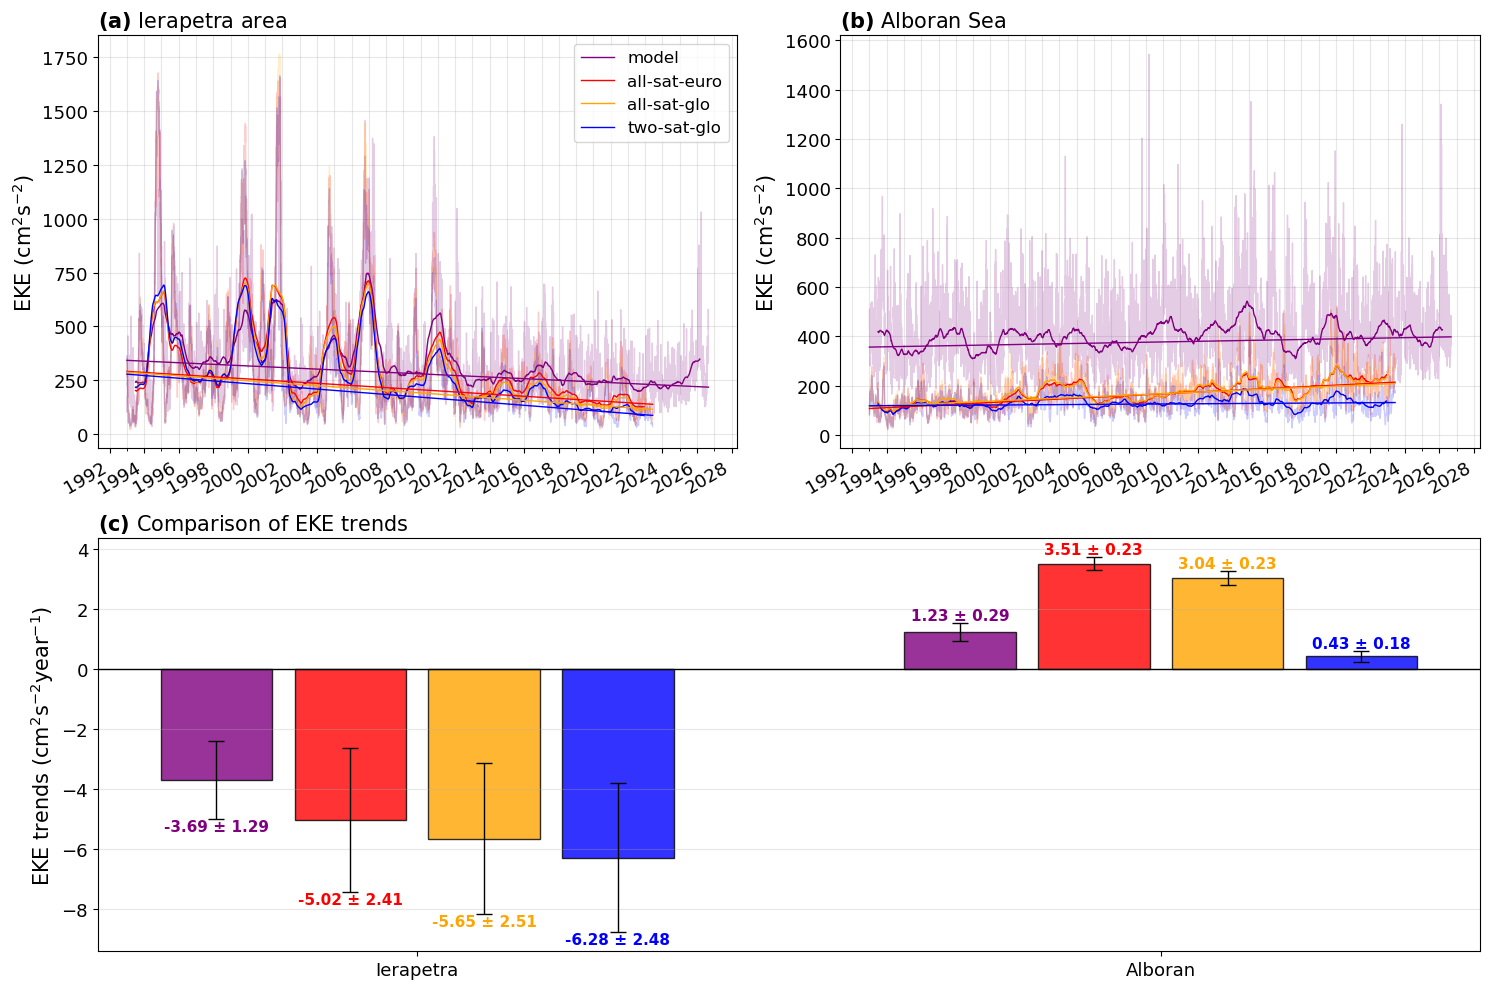

In [36]:
fig = plt.figure(figsize=(15, 10))

gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[1, 1],
    width_ratios=[1, 1],
    figure=fig
)

ax1 = fig.add_subplot(gs[0, 0])   # Ierapetra
ax2 = fig.add_subplot(gs[0, 1])   # Alboran
ax3 = fig.add_subplot(gs[1, :])   # Trends


# ============================================================
# (a) IERAPETRA
# ============================================================

ax1.plot(ds_meanekesurf_iera.time, ds_meanekesurf_iera, color='purple', lw=1, alpha=0.2)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE, color='red', lw=1, alpha=0.2)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE, color='orange', lw=1, alpha=0.2)
ax1.plot(dst_ierab.time, dst_ierab.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax1.plot(ds_meanekesurf_iera.time, ds_meanekesurf_iera.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax1.plot(dsm_ierab.time, dsm_ierab.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax1.plot(dsa_ierab.time, dsa_ierab.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax1.plot(dst_ierab.time, dst_ierab.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekesurf_iera.time.values - ds_meanekesurf_iera.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(ds_meanekesurf_iera.time, sliera / 365 * time_r + interiera,color='purple', linewidth=1, label='model'
        # label=(r'$\beta$ = ' + f'{sliera:.2f}' + r' $\pm$ ' + f'{incertiera:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_ierab.time.values - dsm_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsm_ierab.time, slm_ierab/365 * time_r + interm_ierab, color='red', linewidth=1, label='all-sat-euro')
time_r = ((dsa_ierab.time.values - dsa_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dsa_ierab.time, sla_ierab/365 * time_r + intera_ierab, color='orange', linewidth=1, label='all-sat-glo')
time_r = ((dst_ierab.time.values - dst_ierab.time.values[0]) / np.timedelta64(1, 'D'))
ax1.plot(dst_ierab.time, slt_ierab/365 * time_r + intert_ierab, color='blue', linewidth=1, label='two-sat-glo')

ax1.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)

ax1.set_title(r'$\bf{(a)}$ Ierapetra area', fontsize=15, loc='left')

ax1.legend(fontsize=12, loc='upper right')

ax1.grid(True, which='both', axis='both', alpha=0.3)

ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_minor_locator(mdates.YearLocator(1))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(ax1.xaxis.get_majorticklabels(), rotation=30, ha='right')


# ============================================================
# (b) ALBORAN
# ============================================================

ax2.plot(ds_meanekesurf_alb.time, ds_meanekesurf_alb, color='purple', lw=1, alpha=0.2)
ax2.plot(dsm_alb.time, dsm_alb.EKE, color='red', lw=1, alpha=0.2)
ax2.plot(dsa_alb.time, dsa_alb.EKE, color='orange', lw=1, alpha=0.2)
ax2.plot(dst_alb.time, dst_alb.EKE, color='blue', lw=1, alpha=0.2)
# Moyenne glissante 1 an
ax2.plot(ds_meanekesurf_alb.time, ds_meanekesurf_alb.rolling(time=365, center=True).mean(), color='purple', lw=1)
ax2.plot(dsm_alb.time, dsm_alb.EKE.rolling(time=365, center=True).mean(), color='red', lw=1, alpha=1)
ax2.plot(dsa_alb.time, dsa_alb.EKE.rolling(time=365, center=True).mean(), color='orange', lw=1, alpha=1)
ax2.plot(dst_alb.time, dst_alb.EKE.rolling(time=365, center=True).mean(), color='blue', lw=1, alpha=1)
# Tendance
time_r = ((ds_meanekesurf_alb.time.values - ds_meanekesurf_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(ds_meanekesurf_alb.time, slalb / 365 * time_r + interalb, color='purple', linewidth=1,
        # label=(r'$\beta$ = ' + f'{slalb:.2f}' + r' $\pm$ ' + f'{incertalb:.2f}' + r' cm$^2$s$^{-2}$year$^{-1}$')
        )
time_r = ((dsm_alb.time.values - dsm_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsm_alb.time, slm_alb/365 * time_r + interm_alb, color='red', linewidth=1)
time_r = ((dsa_alb.time.values - dsa_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dsa_alb.time, sla_alb/365 * time_r + intera_alb, color='orange', linewidth=1)
time_r = ((dst_alb.time.values - dst_alb.time.values[0]) / np.timedelta64(1, 'D'))
ax2.plot(dst_alb.time, slt_alb/365 * time_r + intert_alb, color='blue', linewidth=1)

ax2.set_ylabel('EKE (cm$^2$s$^{-2}$)', fontsize=15)

ax2.set_title(r'$\bf{(b)}$ Alboran Sea', fontsize=15, loc='left')

# ax2.legend(fontsize=12, loc='upper left')

ax2.grid(True, which='both', axis='both', alpha=0.3)

ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_minor_locator(mdates.YearLocator(1))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.setp(ax2.xaxis.get_majorticklabels(), rotation=30, ha='right')


# ============================================================
# (c) COMPARAISON DES TENDANCES
# ============================================================

regions = ['Ierapetra', 'Alboran']

slopes_model = [sliera, slalb]
slopes_m = [slm_ierab, slm_alb]
slopes_a = [sla_ierab, sla_alb]
slopes_t = [slt_ierab, slt_alb]

errors_model = [incertiera, incertalb]
errors_m = [incertm_ierab, incertm_alb]
errors_a = [incerta_ierab, incerta_alb]
errors_t = [incertt_ierab, incertt_alb]

pvalues_model = [piera, palb]
pvalues_m = [pm_ierab, pm_alb]
pvalues_a = [pa_ierab, pa_alb]
pvalues_t = [pt_ierab, pt_alb]

xbar = np.arange(len(regions))
offset = 0.18
widthbar = 0.15

color_model = 'purple'
color_m = 'red'
color_a = 'orange'
color_t = 'blue'

all_slopes = [slopes_model, slopes_m, slopes_a, slopes_t]
all_errors = [errors_model, errors_m, errors_a, errors_t]
all_pvalues = [pvalues_model, pvalues_m, pvalues_a, pvalues_t]
all_colors = [color_model, color_m, color_a, color_t]
all_offsets = [-1.5 * offset, -0.5 * offset, 0.5 * offset, 1.5 * offset]

ax3.axhline(0, color='black', linewidth=1)

ax3.set_xticks(xbar)
ax3.set_xticklabels(regions, fontsize=15)

ax3.set_ylabel('EKE trends (cm$^2$s$^{-2}$year$^{-1}$)', fontsize=15)

ax3.set_title(r'$\bf{(c)}$ Comparison of EKE trends', fontsize=15, loc='left')

ax3.grid(True, axis='y', alpha=0.3)

for slopes, errors, pvalues, color, off in zip(all_slopes, all_errors, all_pvalues, all_colors, all_offsets):
    for i, (slope, error, pvalue) in enumerate(zip(slopes, errors, pvalues)):
        if pvalue > 0.05:
                    hatch = '//'
                    fontweight = 'normal'
                    fontstyle = 'italic'
        else:
                    hatch = None
                    fontweight = 'bold'
                    fontstyle = 'normal'
        ax3.bar(xbar[i] + off, slope, widthbar, color=color, alpha=0.8, edgecolor='black', hatch=hatch)
        ax3.errorbar(xbar[i] + off, slope, yerr=error, fmt='none', ecolor='black', elinewidth=1, capsize=6)

        if slope >= 0:
            y = slope + error
            va = 'bottom'
        else:
            y = slope - error
            va = 'top'
        ax3.text(xbar[i] + off, y, f'{slope:.2f} ± {error:.2f}',
            ha='center', va=va, fontsize=11, color=color, fontweight=fontweight, fontstyle=fontstyle)

# ax3.legend(fontsize=12, ncol=4, loc='upper center', bbox_to_anchor=(0.5, 1.02))

# ============================================================
# STYLE
# ============================================================

for ax in [ax1, ax2, ax3]:
    ax.tick_params(axis='both', labelsize=13)

plt.tight_layout()

plt.show()